# NE (LC) and the BWM LD1, within mice

The same question and methods as `4_da_ld1_within_mouse` / `5_ach_ld1_within_mouse` (session LD1 from the BWM
projection; NE measures per fiber-session from `ld1_neural.py`; within-fiber residuals; LD1 permuted within mouse;
controls added step by step: day + protocol, then the session's RT and accuracy, then quiescence wheel speed), for the
**LC-NE** fibers (≥ 5 sessions each; one fiber per mouse here). The VTA results are shown alongside for direction.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import ld1_neural as L

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
TARGET, NM = 'LC-NE', 'NE'
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=None)
T = L.session_table(A, targets=(TARGET,))
PH = ['baseline', 'stim', 'stim_slow', 'reward', 'error', 'reward_hard']
CP = [c for c in T if c.startswith(('β ', 'R² '))]
BASE = ('day', 'protocol')
print(f"{T['subject'].nunique()} mice, {T['fiber'].nunique()} fibers, {T['eid'].nunique()} sessions")
T.groupby('fiber').agg(sessions=('eid', 'size'), LD1_sd=('LD1', 'std'), days=('day_n', lambda s: s.max() - s.min())).round(2)

3 mice, 3 fibers, 83 sessions


,sessions,LD1_sd,days
fiber,,,
ZFM-08652 LC,17,1.11,46
ZFM-08776 LC,31,1.23,57
ZFM-08871 LC,35,1.13,56


In [2]:
#%%
""" SANITY: within mouse, session LD1 vs the same session's behaviour (wheel measures partly circular) """
L.within_fiber(T, ['log_reaction', 'correct', 'wheel_gate', 'paw_gate', 'wheel_speed_Quiescence', 'switches'],
               controls=BASE, n_perm=2000, unit='mouse').round(3)

,measure,r,p,n_sessions,n_fibers,n_mice,q
0,log_reaction,-0.614,0.000,83,3,3,0.001
1,correct,0.126,0.263,83,3,3,0.315
2,wheel_gate,-0.487,0.000,83,3,3,0.001
3,paw_gate,-0.332,0.002,83,3,3,0.003
4,wheel_speed_Quiescence,0.506,0.000,83,3,3,0.001
5,switches,-0.093,0.457,83,3,3,0.457


In [3]:
#%%
""" MAIN: LD1 vs the measures, controls added step by step (r, p, BH q over the measures) """
STEPS = {'day + protocol': BASE, '+ RT + accuracy': BASE + ('log_reaction', 'correct'),
         '+ quiescence wheel': BASE + ('log_reaction', 'correct', 'wheel_speed_Quiescence')}
RES = {k: L.within_fiber(T, PH + CP, controls=c, n_perm=5000, unit='mouse').set_index('measure') for k, c in STEPS.items()}
pd.concat({k: v[['r', 'p', 'q']] for k, v in RES.items()}, axis=1).round(3)

day + protocol               + RT + accuracy               + quiescence wheel              
                                       r      p      q               r      p      q                  r      p      q
measure                                                                                                              
baseline                           0.229  0.027  0.069           0.227  0.046  0.097              0.177  0.120  0.251
stim                              -0.220  0.038  0.072          -0.349  0.001  0.008             -0.330  0.003  0.017
stim_slow                         -0.230  0.030  0.069          -0.269  0.015  0.038             -0.285  0.010  0.026
reward                             0.289  0.005  0.020           0.122  0.286  0.511              0.142  0.221  0.387
error                              0.510  0.000  0.002           0.305  0.005  0.021              0.264  0.015  0.034
reward_hard                        0.018  0.865  0.908           0.036  0.757  0.795             -0.006  0.960  0.960
β paw 0 · pre-stim                -0.108  0.332  0.387          -0.098  0.390  0.585             -0.033  0.768  0.849
β whisking · pre-stim             -0.008  0.947  0.947           0.039  0.734  0.795              0.034  0.757  0.849
β licking · pre-stim               0.187  0.207  0.272           0.098  0.613  0.757              0.256  0.152  0.291
β paw 0 · post-stim               -0.161  0.130  0.182           0.058  0.597  0.757              0.090  0.389  0.584
β whisking · post-stim            -0.262  0.013  0.044          -0.343  0.000  0.004             -0.331  0.002  0.017
β licking · post-stim             -0.200  0.086  0.129          -0.287  0.016  0.038             -0.326  0.006  0.022
β paw 0 · post-fb                  0.538  0.000  0.002           0.309  0.006  0.021              0.309  0.006  0.022
β whisking · post-fb              -0.211  0.062  0.108          -0.084  0.460  0.644             -0.050  0.657  0.849
β licking · post-fb                0.277  0.015  0.044           0.271  0.015  0.038              0.287  0.008  0.025
R² vigor · pre-stim               -0.128  0.269  0.332           0.115  0.292  0.511              0.060  0.587  0.821
R² whisker ME · pre-stim          -0.194  0.080  0.129           0.016  0.885  0.885             -0.010  0.932  0.960
R² vigor · post-stim              -0.321  0.004  0.020          -0.295  0.005  0.021             -0.304  0.003  0.017
R² whisker ME · post-stim         -0.474  0.000  0.003          -0.359  0.000  0.004             -0.413  0.000  0.004
R² vigor · post-fb                -0.240  0.034  0.072          -0.107  0.322  0.520             -0.093  0.383  0.584
R² whisker ME · post-fb           -0.092  0.429  0.474          -0.048  0.658  0.767             -0.032  0.755  0.849

In [4]:
#%%
""" each fiber's own slope (day controlled only): is an effect carried by every mouse or by one? """
S = L.fiber_slopes(T, PH + CP, controls=('day',))
S.pivot(index='measure', columns='fiber', values='r').reindex(PH + CP).round(2)

fiber,ZFM-08652 LC,ZFM-08776 LC,ZFM-08871 LC
measure,,,
baseline,0.34,0.16,0.30
stim,-0.06,-0.22,-0.39
stim_slow,-0.29,-0.45,-0.19
reward,0.59,0.64,-0.07
error,0.49,0.68,0.37
reward_hard,0.35,0.18,-0.23
β paw 0 · pre-stim,-0.04,-0.39,0.08
β whisking · pre-stim,-0.39,0.21,-0.03
β licking · pre-stim,-0.06,0.73,0.19


In [5]:
#%%
""" the same measures in VTA (4_da_ld1_within_mouse), for direction: + RT + accuracy """
Tv = L.session_table(A, targets=('VTA-DA',))
VTA = L.within_fiber(Tv, PH + CP, controls=STEPS['+ RT + accuracy'], n_perm=2000).set_index('measure')
cmp_ = RES['+ RT + accuracy'][['r', 'p', 'q']].add_suffix(f' {NM}').join(VTA[['r', 'q']].add_suffix(' VTA'))
print('profile agreement across measures, r(' + NM + ', VTA) =', round(cmp_[[f'r {NM}', 'r VTA']].corr().iloc[0, 1], 2))
cmp_.round(3)

profile agreement across measures, r(NE, VTA) = -0.25


,r NE,p NE,q NE,r VTA,q VTA
measure,,,,,
baseline,0.227,0.046,0.097,0.074,0.522
stim,-0.349,0.001,0.008,0.256,0.016
stim_slow,-0.269,0.015,0.038,0.131,0.347
reward,0.122,0.286,0.511,-0.162,0.187
error,0.305,0.005,0.021,-0.056,0.569
reward_hard,0.036,0.757,0.795,0.081,0.522
β paw 0 · pre-stim,-0.098,0.390,0.585,0.187,0.178
β whisking · pre-stim,0.039,0.734,0.795,0.351,0.010
β licking · pre-stim,0.098,0.613,0.757,0.149,0.455


## Traces binned along LD1

Each fiber's sessions split into thirds by LD1, averaged within mouse and third, then across mice (shading = SEM across
mice). Binned on LD1 alone: the movement panels show what else differs between the thirds.

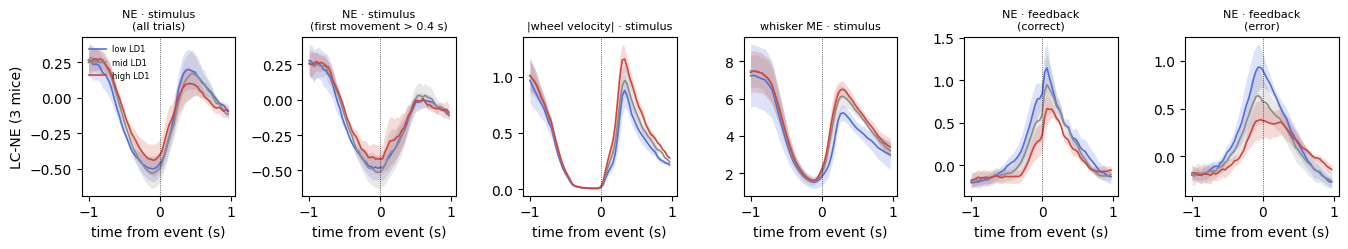

In [6]:
#%%
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import paper_style as ps
TR = L.traces(sorted(T['eid'].unique()))
PANELS = [('stim_all', NM + ' · stimulus\n(all trials)'), ('stim_slow', NM + ' · stimulus\n(first movement > 0.4 s)'),
          ('stim wheel speed', '|wheel velocity| · stimulus'), ('stim whisker ME', 'whisker ME · stimulus'),
          ('fb_correct', NM + ' · feedback\n(correct)'), ('fb_error', NM + ' · feedback\n(error)')]
BIN_COL = [ps.LD1_CMAP(0.08), '0.55', ps.LD1_CMAP(0.92)]
fig, axes = plt.subplots(1, len(PANELS), figsize=(2.25 * len(PANELS), 2.6), sharex=True)
for ax, (key, title) in zip(axes, PANELS):
    t, out = L.binned_traces(T, TR, key, unit='subject')
    for b, (m, se) in out.items():
        ax.plot(t, m, color=BIN_COL[b], lw=1.2, label=['low', 'mid', 'high'][b] + ' LD1')
        ax.fill_between(t, m - se, m + se, color=BIN_COL[b], alpha=0.2, lw=0)
    ax.axvline(0, color='k', lw=0.5, ls=':')
    ax.set_title(title, fontsize=8); ax.set_xlabel('time from event (s)')
axes[0].set_ylabel(f"{TARGET} ({T['subject'].nunique()} mice)")
axes[0].legend(fontsize=6, frameon=False, loc='upper left')
plt.tight_layout()
pathlib.Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/ne_ld1_traces.png', dpi=250, bbox_inches='tight')
plt.show()

## Reading

- **Session LD1 is a behavioural-state axis here**: within mouse it tracks RT (−0.61), wheel / paw gating and
  quiescence movement (q ≤ 0.003), as in the DA mice.
- **NE changes with LD1, in the opposite direction to VTA** (profile across measures r = −0.25), and every effect below
  has the same sign in all three mice:
  - **smaller stimulus response at high LD1** (−0.35, q = 0.008 with RT and accuracy controlled; −0.33 with quiescence
    wheel speed too), also on trials whose movement comes after the window (−0.27, q = 0.04) — so not explained by
    movement, which is *larger* at high LD1;
  - **smaller response / feedback transient at high LD1** (traces: the peak at feedback, correct and error, is largest
    in low-LD1 sessions). Caveat: NE rises *before* feedback, so the baseline-corrected `error` / `reward` measures
    (which subtract [−0.2, 0) s) come out with the opposite sign (+0.31): read the traces, not those two numbers;
  - **less movement coupling right after the stimulus** (whisking β −0.34, whisker R² −0.36, vigor R² −0.30;
    q ≤ 0.02), and more still-paw coupling after feedback (+0.31, q = 0.02).
- Only 3 mice (83 sessions): consistent within each, but a small cohort.

So: in high-LD1 sessions (faster, more movement through the hold) LC-NE transients around stimulus and choice are
*smaller* and less tied to whisking, the mirror image of VTA DA. Worth a trial-level model before trusting it.